# 电商用户行为分析报告

**数据范围**：2024-01 ~ 2025-12（24 个月，5,000 名用户，400 个商品，46,348 条订单）
**分析口径**：已支付订单（不含退款、取消、退货）

**一句话结论**：平台 GMV 24 个月增长约 50 倍，但增长高度依赖少数头部城市与单一品类，且新客占比持续走低，后续应从"拉新驱动"转向"存量精细化运营"。

## 1. 背景与目标

平台 GMV 增长较快，但管理层更关心增长的质量。本次分析回答三个问题：

1. 增长来自哪里，是否能持续；
2. 收入和用户集中在哪些城市与品类；
3. 用户的复购与拉新情况如何，运营资源应该往哪里倾斜。

## 2. 数据说明

| 表 | 行数 | 关键字段 |
|---|---|---|
| users | 5,000 | user_id, register_date, city, channel, age_group |
| products | 400 | product_id, category, price |
| orders | 46,348 | order_id, user_id, product_id, order_date, quantity, amount, status |

**数据质量问题（清洗前体检结果）**

| 问题 | 数量 | 占比 | 处理 |
|---|---|---|---|
| 重复 order_id | 138 | 0.30% | 按 order_id 去重 |
| 金额缺失 | 462 | 1.00% | 保留原始行，分析时排除 |
| 退货记录（quantity < 0） | 231 | 0.50% | 标记 is_return，GMV 剔除 |
| 城市缺失 | 50 | 1.00% | 填充为"未知" |

In [1]:
import pandas as pd

orders = pd.read_csv('../data/orders.csv', parse_dates=['order_date'])
users = pd.read_csv('../data/users.csv')
products = pd.read_csv('../data/products.csv')

print('orders  ', orders.shape)
print('users   ', users.shape)
print('products', products.shape)

orders   (46348, 8)
users    (5000, 6)
products (400, 3)


## 3. 数据清洗

清洗规则按业务含义确定，不做"一刀切删除"：

- **去重**：order_id 是业务主键，重复记录保留首条；
- **金额缺失**：缺失订单无法计算 GMV，但原始行保留，分析时用有效订单口径；
- **退货**：quantity 为负的记录单独标记，避免冲减 GMV；
- **城市缺失**：填充为"未知"，不丢弃用户。

In [2]:
df = orders.copy()
raw = len(df)

# 1) 去重
df = df.drop_duplicates(subset=['order_id'])

# 2) 金额缺失
null_amount = df['amount'].isna().sum()

# 3) 退货标记
df['is_return'] = df['quantity'] < 0
returns = int(df['is_return'].sum())

# 4) 城市缺失
users['city'] = users['city'].fillna('未知')

# 5) 有效订单口径
paid = df[(df['status'] == '已支付') & (~df['is_return']) & df['amount'].notna()]

print(f'原始订单    {raw:,}')
print(f'去重后      {len(df):,}')
print(f'金额缺失    {null_amount:,}')
print(f'退货单      {returns:,}')
print(f'有效订单    {len(paid):,}')

原始订单    46,348
去重后      46,210
金额缺失    462
退货单      231
有效订单    41,881


## 4. 核心指标

| 指标 | 定义 | 结果 |
|---|---|---|
| GMV | 已支付订单金额之和 | 35,890,917 元 |
| 订单数 | 已支付且非退货订单 | 41,881 单 |
| 客单价 AOV | GMV / 订单数 | 856.97 元 |
| 复购率 | 下单 ≥2 次用户 / 下单用户 | 86.95% |
| 覆盖用户 | 有有效订单的用户数 | 3,947 人 |

> 注：复购率显著高于真实电商（通常 30%–40%），源数据为模拟生成，见第 7 节局限。

In [3]:
gmv = paid['amount'].sum()
order_cnt = len(paid)
aov = gmv / order_cnt

buy_cnt = paid.groupby('user_id').size()
repurchase = (buy_cnt >= 2).mean()

print(f'GMV       {gmv:,.0f}')
print(f'订单数     {order_cnt:,}')
print(f'客单价     {aov:,.2f}')
print(f'复购率     {repurchase:.2%}')
print(f'覆盖用户   {len(buy_cnt):,}')

GMV       35,890,917
订单数     41,881
客单价     856.97
复购率     86.95%
覆盖用户   3,947


## 5. 可视化

### 5.1 月度 GMV 趋势

![月度GMV](../images/01_月度GMV.png)

GMV 从 2024 年 1 月的 5.5 万增长至 2025 年 12 月的 281.9 万，2025 年 9 月达到峰值 291.3 万后增速放缓。

### 5.2 城市维度

![城市GMV](../images/02_城市GMV.png)

北京、上海、深圳、广州四城合计贡献约 56% 的 GMV，头部集中度较高。

### 5.3 品类结构

![品类占比](../images/03_品类占比.png)

数码品类 GMV 1,266.7 万，占比约 35.1%，是绝对主力；家居、服饰、运动构成第二梯队。

### 5.4 新客占比

![新客占比](../images/04_新客占比.png)

新客占比从 2024 年 1 月的 100% 降至 2025 年 12 月的 0.07%，增长明显依赖存量复购。

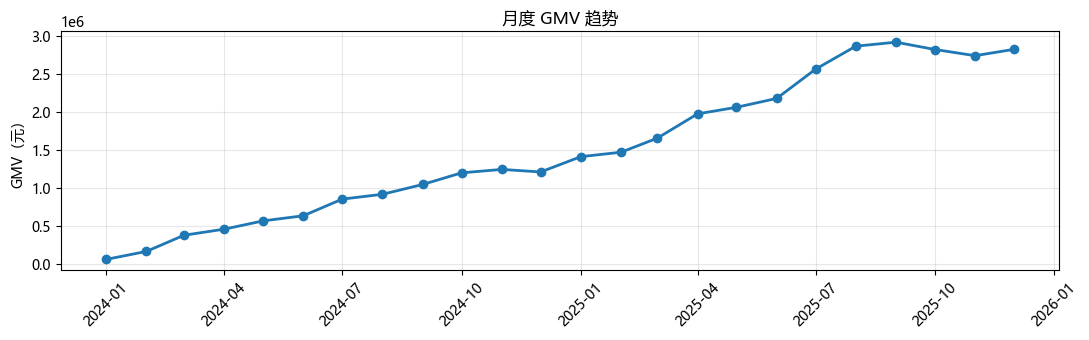

In [4]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

m = pd.read_csv('../data/monthly_gmv.csv')
m['ym'] = pd.to_datetime(m['ym'].astype(str) + '-01')

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(m['ym'], m['gmv'], marker='o', linewidth=2)
ax.set_title('月度 GMV 趋势')
ax.set_ylabel('GMV（元）')
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. 结论与建议

**① 增长进入平台期。** GMV 24 个月增长约 50 倍，但 2025 年 9 月见顶后趋平，增长动力从"用户涌入"转向"存量经营"。

**② 收入集中在头部城市。** 北上深广贡献 56% 的 GMV。建议头部城市维持投入，同时对武汉等尾部城市单独核算获客成本，避免资源摊薄。

**③ 品类结构单一。** 数码占 35.1%，单一品类波动会显著影响整体收入。建议评估家居、运动的增长空间，降低结构性风险。

**④ 拉新乏力是主要隐患。** 新客占比趋近于零、复购率 87%，说明现有用户黏性高但新增不足。建议把预算从"泛投"转向"老客裂变 + 品类拓展"。

## 7. 局限与下一步

- 数据为**模拟生成**，用户行为分布偏理想化（复购率 87% 显著高于真实水平），结论用于验证分析流程，不代表真实业务判断；
- 新客占比后期接近 0，源于模拟数据中注册集中在前期，属数据构造问题；
- 未考虑退款冲减、优惠券成本、渠道成本等口径；
- 下一步：RFM + K-Means 用户分群、流失预警模型、渠道 ROI 分析。